# 리뷰 스코어링 + 마스터 데이터셋 생성

이 노트북은 **`olist_review_text_mining.ipynb`(경로 B)** 의 후속 작업입니다.

## 목적
1. **모든 리뷰**(텍스트 없는 것 포함, 99,224건)에 감성 점수 + 라벨 부여
2. **평점 ↔ 텍스트 감성** 일치/불일치 라벨링 (`mismatch_type`)
3. orders / items / products / sellers / customers / payments 조인
4. 두 그레인의 **마스터 데이터셋** 생성:
   - `master_review_level.csv` — 리뷰 1건 = 1행 (다른 변수와 관계 분석용)
   - `master_review_item_level.csv` — 리뷰 × 상품 × 판매자 (카테고리/판매자 분석용)
5. 미스매치 케이스의 카테고리 / 판매자 분포 분석

---
## 1. 모든 리뷰에 감성 점수·라벨 부여

**사전 + 부정문 처리 방식**으로 직접 점수화 (번역 없이 포르투갈어 그대로). 
VADER 감성점수가 이미 있다면 그걸 사용해도 OK.

In [1]:
import pandas as pd
import numpy as np
import re

reviews_raw = pd.read_csv('olist_order_reviews_dataset.csv')
reviews_raw['review_comment_message'] = reviews_raw['review_comment_message'].fillna('')

print(f'전체 리뷰: {len(reviews_raw):,}건')
print(f'  - 텍스트 있음: {(reviews_raw["review_comment_message"]!="").sum():,}건')
print(f'  - 텍스트 없음: {(reviews_raw["review_comment_message"]=="").sum():,}건')

전체 리뷰: 99,224건
  - 텍스트 있음: 40,977건
  - 텍스트 없음: 58,247건


In [2]:
# 포르투갈어 감성 사전
positive_words = {
    'ótimo':2,'otimo':2,'ótima':2,'otima':2,'excelente':2,'excelentes':2,
    'perfeito':2,'perfeita':2,'maravilhoso':2,'maravilhosa':2,
    'amei':2,'adorei':2,'amo':2,'gostei':1,'gosto':1,
    'bom':1,'boa':1,'bons':1,'boas':1,'bem':1,
    'recomendo':2,'recomendado':1,'recomendada':1,
    'super':1,'top':1,'lindo':1,'linda':1,'lindas':1,'lindos':1,
    'rápido':1,'rapida':1,'rapido':1,'rápida':1,
    'satisfeito':1,'satisfeita':1,'satisfação':1,
    'parabéns':1,'parabens':1,'aprovado':1
}
negative_words = {
    'péssimo':-2,'pessimo':-2,'péssima':-2,'pessima':-2,
    'horrível':-2,'horrivel':-2,'terrível':-2,'terrivel':-2,
    'ruim':-2,'ruins':-2,'lixo':-2,'porcaria':-2,
    'defeito':-2,'defeituoso':-2,'defeituosa':-2,'quebrado':-2,'quebrada':-2,
    'errado':-1,'errada':-1,'falta':-1,'faltou':-1,'faltando':-1,
    'decepção':-2,'decepcionado':-2,'decepcionada':-2,'decepcionante':-2,
    'devolver':-1,'devolução':-1,'devolucao':-1,'reembolso':-1,
    'cancelar':-1,'cancelado':-1,
    'atrasado':-1,'atrasada':-1,'atraso':-1,'demorou':-1,'demora':-1,
    'pior':-1,'arrependi':-2,'fraco':-1,'fraca':-1,
    'roubo':-2,'fraude':-2
}
negators = {'não','nao','nem','nunca','jamais'}
neg_followers = {'recebi','recebido','chegou','chegei','veio','funciona','recomendo','gostei'}

def score_text(text):
    """감성 점수와 매칭 단어 수를 함께 반환"""
    if not text or pd.isna(text):
        return 0, 0
    t = re.sub(r'[^a-záàâãéèêíïóôõöúüç\s]', ' ', str(text).lower())
    words = t.split()
    score, matches = 0, 0
    for i, w in enumerate(words):
        prev_neg = (i > 0 and words[i-1] in negators)
        if w in positive_words:
            score += -positive_words[w] if prev_neg else positive_words[w]
            matches += 1
        elif w in negative_words:
            score += negative_words[w]
            matches += 1
        # 'não recebi', 'não chegou' 같은 표현 추가 점수
        if w in {'não','nao'} and i+1 < len(words) and words[i+1] in neg_followers:
            score -= 2
            matches += 1
    return score, matches

scores = reviews_raw['review_comment_message'].apply(score_text)
reviews_raw['sent_score']   = scores.apply(lambda x: x[0])
reviews_raw['sent_matches'] = scores.apply(lambda x: x[1])
reviews_raw['text_length']  = reviews_raw['review_comment_message'].str.len()
reviews_raw['has_text']     = reviews_raw['text_length'] > 0

reviews_raw[['review_id','review_score','sent_score','sent_matches','text_length']].head()

,review_id,review_score,sent_score,sent_matches,text_length
0,7bc2406110b926393aa56f80a40eba40,4,0,0,0
1,80e641a11e56f04c1ad469d5645fdfde,5,0,0,0
2,228ce5500dc1d8e020d8d1322874b6f0,5,0,0,0
3,e64fb393e7b32834bb789ff8bb30750e,5,1,1,37
4,f7c4243c7fe1938f181bec41a392bdeb,5,4,3,100


In [3]:
# 감성 라벨 (positive / neutral / negative / no_text)
def label(s, has):
    if not has: return 'no_text'
    if s >= 1: return 'positive'
    elif s <= -1: return 'negative'
    return 'neutral'

reviews_raw['sent_label'] = reviews_raw.apply(
    lambda r: label(r['sent_score'], r['has_text']), axis=1)

# 평점 카테고리 (high=4-5, mid=3, low=1-2)
def rating_cat(r):
    if r >= 4: return 'high'
    elif r <= 2: return 'low'
    return 'mid'
reviews_raw['rating_cat'] = reviews_raw['review_score'].apply(rating_cat)

# ⭐ 미스매치 타입 — 여기가 핵심 라벨
def mismatch_type(row):
    if not row['has_text']: return 'no_text'
    rc, sl = row['rating_cat'], row['sent_label']
    if rc == 'high' and sl == 'negative': return 'high_rating_negative_text'   # ⚠️ 4-5점인데 부정 텍스트
    if rc == 'low'  and sl == 'positive': return 'low_rating_positive_text'    # ⚠️ 1-2점인데 긍정 텍스트
    if rc == 'high' and sl == 'positive': return 'aligned_positive'
    if rc == 'low'  and sl == 'negative': return 'aligned_negative'
    return 'mid_or_neutral'

reviews_raw['mismatch_type'] = reviews_raw.apply(mismatch_type, axis=1)

# 신뢰도 — 매칭된 감성 단어 개수가 적으면 점수 신뢰도 낮음
def confidence(row):
    if not row['has_text']: return 'low'
    if row['sent_matches'] >= 3: return 'high'
    if row['sent_matches'] >= 1: return 'medium'
    return 'low'
reviews_raw['sent_confidence'] = reviews_raw.apply(confidence, axis=1)

print('✅ 모든 리뷰 점수화/라벨링 완료\n')
print('미스매치 타입 분포:')
print(reviews_raw['mismatch_type'].value_counts())

✅ 모든 리뷰 점수화/라벨링 완료

미스매치 타입 분포:
mismatch_type
no_text                      58247
aligned_positive             18640
mid_or_neutral               15773
aligned_negative              5255
high_rating_negative_text      729
low_rating_positive_text       580
Name: count, dtype: int64


---
## 2. 다른 데이터셋 로드 + 조인

orders / order_items / products / sellers / customers / payments 모두 결합.

In [4]:
orders     = pd.read_csv('olist_orders_dataset.csv')
items      = pd.read_csv('olist_order_items_dataset.csv')
products   = pd.read_csv('olist_products_dataset.csv')
customers  = pd.read_csv('olist_customers_dataset.csv')
sellers    = pd.read_csv('olist_sellers_dataset.csv')
payments   = pd.read_csv('olist_order_payments_dataset.csv')
cat_trans  = pd.read_csv('product_category_name_translation.csv')

# 카테고리 영문명 부착
products = products.merge(cat_trans, on='product_category_name', how='left')

# 결제: 한 주문에 여러 결제 가능 → 합산
pay_agg = payments.groupby('order_id').agg(
    payment_value=('payment_value','sum'),
    payment_type=('payment_type', lambda x: x.mode().iat[0] if len(x.mode())>0 else 'unknown'),
    payment_installments=('payment_installments','max')
).reset_index()

# 주문 + 고객 + 결제
order_full = (orders
    .merge(customers, on='customer_id', how='left')
    .merge(pay_agg,   on='order_id',    how='left'))

# 배송 일자 → datetime
for c in ['order_purchase_timestamp','order_delivered_customer_date','order_estimated_delivery_date']:
    order_full[c] = pd.to_datetime(order_full[c], errors='coerce')

order_full['delivery_days']       = (order_full['order_delivered_customer_date']
                                     - order_full['order_purchase_timestamp']).dt.days
order_full['delivery_delay_days'] = (order_full['order_delivered_customer_date']
                                     - order_full['order_estimated_delivery_date']).dt.days
order_full['is_late'] = order_full['delivery_delay_days'] > 0

# 아이템 + 상품 + 판매자
item_full = (items
    .merge(products[['product_id','product_category_name','product_category_name_english',
                     'product_weight_g','product_photos_qty']], on='product_id', how='left')
    .merge(sellers, on='seller_id', how='left'))

print(f'order_full: {len(order_full):,} rows')
print(f'item_full:  {len(item_full):,} rows')

order_full: 99,441 rows
item_full:  112,650 rows


---
## 3. 두 그레인의 마스터 데이터셋 생성

### A) review-level — 리뷰 1건 = 1행 (다른 변수와 관계 분석에 가장 적합)

In [5]:
review_cols = ['review_id','order_id','review_score','review_comment_title','review_comment_message',
               'review_creation_date','sent_score','sent_matches','text_length','has_text',
               'sent_label','rating_cat','mismatch_type','sent_confidence']

order_cols  = ['order_id','customer_id','customer_unique_id','customer_city','customer_state',
               'order_status','order_purchase_timestamp','order_delivered_customer_date',
               'order_estimated_delivery_date','delivery_days','delivery_delay_days','is_late',
               'payment_value','payment_type','payment_installments']

master_review = reviews_raw[review_cols].merge(order_full[order_cols], on='order_id', how='left')

# 한 주문에 여러 아이템 가능 → 주문 단위로 집계해서 컬럼 추가
item_agg = items.groupby('order_id').agg(
    n_items=('order_item_id','count'),
    total_price=('price','sum'),
    total_freight=('freight_value','sum'),
    n_unique_products=('product_id','nunique'),
    n_unique_sellers=('seller_id','nunique')
).reset_index()
master_review = master_review.merge(item_agg, on='order_id', how='left')

# 대표 카테고리 — 가장 비싼 상품의 카테고리
top_item = (items.merge(products[['product_id','product_category_name_english']], on='product_id')
            .sort_values('price', ascending=False)
            .drop_duplicates('order_id'))[['order_id','product_category_name_english']]
top_item = top_item.rename(columns={'product_category_name_english':'main_category'})
master_review = master_review.merge(top_item, on='order_id', how='left')

print(f'✅ master_review: {master_review.shape[0]:,} rows × {master_review.shape[1]} cols')
master_review.head(3)

✅ master_review: 99,224 rows × 34 cols


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,sent_score,sent_matches,text_length,has_text,...,is_late,payment_value,payment_type,payment_installments,n_items,total_price,total_freight,n_unique_products,n_unique_sellers,main_category
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,,2018-01-18 00:00:00,0,0,0,False,...,False,397.26,credit_card,8.0,2.0,370.00,27.26,1.0,1.0,sports_leisure
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,,2018-03-10 00:00:00,0,0,0,False,...,False,88.09,credit_card,1.0,1.0,79.79,8.30,1.0,1.0,computers_accessories
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,,2018-02-17 00:00:00,0,0,0,False,...,False,194.12,credit_card,1.0,1.0,149.00,45.12,1.0,1.0,computers_accessories


### B) review-item-level — 리뷰 × 상품 × 판매자 조합 1행 (카테고리/판매자 분석용)

In [6]:
master_item = (reviews_raw[review_cols]
    .merge(item_full[['order_id','order_item_id','product_id','seller_id',
                       'product_category_name','product_category_name_english',
                       'price','freight_value','seller_city','seller_state']],
           on='order_id', how='left')
    .merge(order_full[['order_id','customer_unique_id','customer_city','customer_state',
                       'delivery_days','delivery_delay_days','is_late']],
           on='order_id', how='left'))

print(f'✅ master_item: {master_item.shape[0]:,} rows × {master_item.shape[1]} cols')
master_item.head(3)

✅ master_item: 113,131 rows × 29 cols


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,sent_score,sent_matches,text_length,has_text,...,price,freight_value,seller_city,seller_state,customer_unique_id,customer_city,customer_state,delivery_days,delivery_delay_days,is_late
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,,2018-01-18 00:00:00,0,0,0,False,...,185.00,13.63,sao joaquim da barra,SP,68a5590b9926689be4e10f4ae2db21a8,osasco,SP,6.0,-16.0,False
1,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,,2018-01-18 00:00:00,0,0,0,False,...,185.00,13.63,sao joaquim da barra,SP,68a5590b9926689be4e10f4ae2db21a8,osasco,SP,6.0,-16.0,False
2,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,,2018-03-10 00:00:00,0,0,0,False,...,79.79,8.30,sao jose dos campos,SP,64190b91b656ab8f37eb89b93dc84584,nova odessa,SP,9.0,-5.0,False


In [7]:
# 두 데이터셋 저장
master_review.to_csv('master_review_level.csv', index=False)
master_item.to_csv('master_review_item_level.csv', index=False)
print('💾 master_review_level.csv 저장')
print('💾 master_review_item_level.csv 저장')

💾 master_review_level.csv 저장
💾 master_review_item_level.csv 저장


---
## 4. 미스매치 케이스 — 카테고리 / 판매자 랭킹

In [8]:
# 4-1) 5점인데 부정 텍스트 — Top 카테고리
print('🔴 [5점인데 부정 텍스트] Top 15 카테고리')
top_cat_5neg = (master_item[master_item['mismatch_type']=='high_rating_negative_text']
    .groupby('product_category_name_english').size()
    .sort_values(ascending=False).head(15))
print(top_cat_5neg)

🔴 [5점인데 부정 텍스트] Top 15 카테고리
product_category_name_english
bed_bath_table           89
computers_accessories    65
telephony                62
health_beauty            60
sports_leisure           59
furniture_decor          50
housewares               45
watches_gifts            38
cool_stuff               36
garden_tools             28
auto                     28
toys                     27
office_furniture         27
electronics              24
baby                     20
dtype: int64


In [9]:
# 4-2) 1점인데 긍정 텍스트 — Top 카테고리
print('🟢 [1점인데 긍정 텍스트] Top 15 카테고리')
top_cat_1pos = (master_item[master_item['mismatch_type']=='low_rating_positive_text']
    .groupby('product_category_name_english').size()
    .sort_values(ascending=False).head(15))
print(top_cat_1pos)

🟢 [1점인데 긍정 텍스트] Top 15 카테고리
product_category_name_english
bed_bath_table           98
furniture_decor          54
computers_accessories    52
watches_gifts            48
health_beauty            47
housewares               41
sports_leisure           31
perfumery                29
garden_tools             28
auto                     27
cool_stuff               26
telephony                26
baby                     23
toys                     17
electronics              15
dtype: int64


In [10]:
# 4-3) 카테고리별 발생률 — '5점 리뷰 100건 중 부정 텍스트 몇 건?'
high = master_review[master_review['rating_cat']=='high'].copy()
high['is_neg'] = (high['mismatch_type']=='high_rating_negative_text').astype(int)

cat_rate = (high.groupby('main_category').agg(
    n_high_rating=('review_id','count'),
    n_with_neg_text=('is_neg','sum'))
    .assign(pct=lambda d: (d['n_with_neg_text']/d['n_high_rating']*100).round(2))
    .query('n_high_rating >= 200')
    .sort_values('pct', ascending=False)
    .head(15))
print('카테고리별 5점-부정 발생률 Top 15 (최소 200건 이상):')
print(cat_rate)

카테고리별 5점-부정 발생률 Top 15 (최소 200건 이상):
                       n_high_rating  n_with_neg_text   pct
main_category                                              
office_furniture                 796               19  2.39
telephony                       3104               57  1.84
furniture_living_room            310                5  1.61
home_confort                     255                4  1.57
consoles_games                   792               12  1.52
home_appliances                  637                9  1.41
small_appliances                 504                7  1.39
cool_stuff                      2854               35  1.23
electronics                     1970               22  1.12
home_construction                360                4  1.11
food                             369                4  1.08
bed_bath_table                  6861               72  1.05
computers_accessories           5066               52  1.03
market_place                     207                2  0.97
spo

In [11]:
# 4-4) 의심 판매자 — 5점 부정 케이스가 많은 판매자 + 전체 통계
seller_stats = (master_item.groupby('seller_id').agg(
    total_reviews=('review_id','count'),
    n_5neg=('mismatch_type', lambda x: (x=='high_rating_negative_text').sum()),
    n_1pos=('mismatch_type', lambda x: (x=='low_rating_positive_text').sum()),
    avg_rating=('review_score','mean'),
    avg_sent=('sent_score','mean'),
    seller_state=('seller_state','first')
).round(2))
seller_stats['pct_5neg'] = (seller_stats['n_5neg']/seller_stats['total_reviews']*100).round(2)

suspect = seller_stats[seller_stats['n_5neg']>=10].sort_values('pct_5neg', ascending=False).head(15)
print('🔴 의심 판매자 Top 15 (5점-부정 ≥10건, pct_5neg 높은 순):')
print(suspect)

suspect.to_csv('suspect_sellers.csv')
print('\n💾 suspect_sellers.csv 저장')

🔴 의심 판매자 Top 15 (5점-부정 ≥10건, pct_5neg 높은 순):
                                  total_reviews  n_5neg  n_1pos  avg_rating  \
seller_id                                                                     
7ddcbb64b5bc1ef36ca8c151f6ec77df            341      10       6        3.90   
ea8482cd71df3c1969d7b9473ff13abc           1197      20       8        3.95   
7c67e1448b00f6e969d365cea6b010ab           1367      20       9        3.35   
4a3ca9315b744ce9f8e9374361493884           1984      27      21        3.80   
da8622b14eb17ae2831f4ac5b9dab84a           1568      16      14        4.07   
3d871de0142ce09b7081e2b9d1733cb1           1136      11       2        4.11   
1f50f920176fa81dab994f9023523100           1932      15      15        3.98   
1025f0e2d44d7041d6cf58b6550e0bfa           1431      11      10        3.85   
6560211a19b47992c3666cc44a7e94c0           2020      14      26        3.91   

                                  avg_sent seller_state  pct_5neg  
seller_id        

---
## 5. 활용 예시 — 미스매치 ↔ 다른 변수 관계

In [12]:
# 5-1) 배송 지연 vs 미스매치 타입
print('미스매치 타입별 평균 배송 지연(일) — +면 늦음, -면 일찍 도착')
print('-'*60)
delay_by = (master_review.groupby('mismatch_type').agg(
    n=('review_id','count'),
    avg_delay_days=('delivery_delay_days','mean'),
    pct_late=('is_late', lambda x: x.sum()/x.notna().sum()*100))
    .round(1)
    .sort_values('avg_delay_days', ascending=False))
print(delay_by)

미스매치 타입별 평균 배송 지연(일) — +면 늦음, -면 일찍 도착
------------------------------------------------------------
                               n  avg_delay_days  pct_late
mismatch_type                                             
aligned_negative            5255            -4.3      29.8
low_rating_positive_text     580            -9.3      15.9
high_rating_negative_text    729           -10.3      10.3
mid_or_neutral             15773           -10.8      10.5
no_text                    58247           -12.3       4.5
aligned_positive           18640           -13.6       2.0


/var/folders/3z/x60jqlxn6vx6dd5wzhzxq0100000gn/T/ipykernel_34516/1710939080.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='mismatch_type', y='delivery_delay_days',


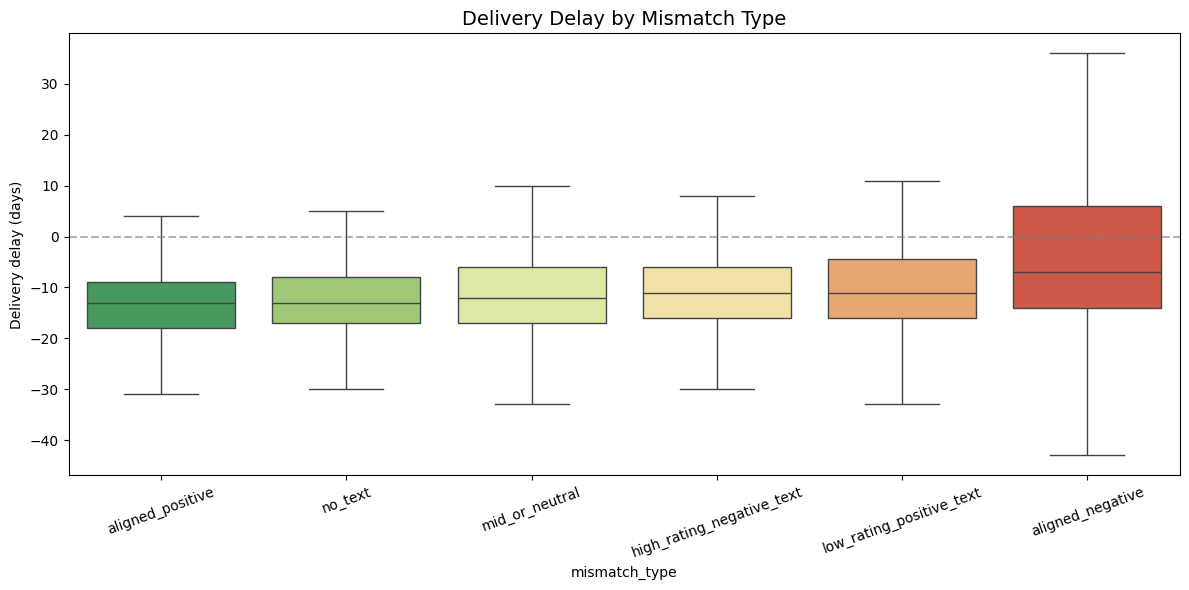

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 5-2) 시각화 — 미스매치 타입 × 배송 지연
plot_df = master_review.dropna(subset=['delivery_delay_days']).copy()
order = ['aligned_positive','no_text','mid_or_neutral',
         'high_rating_negative_text','low_rating_positive_text','aligned_negative']
plot_df = plot_df[plot_df['mismatch_type'].isin(order)]
plot_df['mismatch_type'] = pd.Categorical(plot_df['mismatch_type'], categories=order, ordered=True)

plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_df, x='mismatch_type', y='delivery_delay_days',
            showfliers=False, palette='RdYlGn_r')
plt.axhline(0, color='gray', linestyle='--', alpha=0.6)
plt.title('Delivery Delay by Mismatch Type', fontsize=14)
plt.xticks(rotation=20)
plt.ylabel('Delivery delay (days)')
plt.tight_layout()
plt.savefig('delay_vs_mismatch.png', dpi=200, bbox_inches='tight')
plt.show()

In [14]:
# 5-3) 미스매치 vs 결제 방법
print('미스매치 타입별 결제 방법 분포(%):')
print('-'*60)
pay_dist = (pd.crosstab(master_review['mismatch_type'],
                        master_review['payment_type'],
                        normalize='index')*100).round(1)
print(pay_dist)

미스매치 타입별 결제 방법 분포(%):
------------------------------------------------------------
payment_type               boleto  credit_card  debit_card  not_defined  \
mismatch_type                                                             
aligned_negative             19.4         76.9         1.3          0.0   
aligned_positive             19.9         76.6         1.6          0.0   
high_rating_negative_text    19.9         76.8         1.6          0.0   
low_rating_positive_text     20.7         74.5         1.6          0.0   
mid_or_neutral               20.1         76.1         1.6          0.0   
no_text                      19.9         76.6         1.5          0.0   

payment_type               voucher  
mismatch_type                       
aligned_negative               2.4  
aligned_positive               1.9  
high_rating_negative_text      1.6  
low_rating_positive_text       3.3  
mid_or_neutral                 2.1  
no_text                        2.0  


In [15]:
# 5-4) 고객 주(state) 별 미스매치 발생률
print('고객 주별 미스매치 비율 Top 10 (1000건 이상 주만):')
print('-'*60)
state_stats = (master_review.groupby('customer_state').agg(
    n=('review_id','count'),
    n_mismatch=('mismatch_type', lambda x: x.isin(
        ['high_rating_negative_text','low_rating_positive_text']).sum()))
    .assign(pct=lambda d: (d['n_mismatch']/d['n']*100).round(2))
    .query('n >= 1000')
    .sort_values('pct', ascending=False)
    .head(10))
print(state_stats)

고객 주별 미스매치 비율 Top 10 (1000건 이상 주만):
------------------------------------------------------------
                    n  n_mismatch   pct
customer_state                         
BA               3357          66  1.97
PE               1646          29  1.76
CE               1329          22  1.66
GO               2024          31  1.53
RJ              12765         192  1.50
SC               3623          49  1.35
MG              11625         156  1.34
DF               2148          26  1.21
SP              41690         496  1.19
ES               2016          23  1.14


In [16]:
# 5-5) 결제액과 미스매치의 관계
print('미스매치 타입별 평균 결제액(BRL):')
print('-'*60)
print(master_review.groupby('mismatch_type')['payment_value']
      .agg(['mean','median','count']).round(2))

미스매치 타입별 평균 결제액(BRL):
------------------------------------------------------------
                             mean  median  count
mismatch_type                                   
aligned_negative           193.45  119.70   5254
aligned_positive           159.47  106.89  18640
high_rating_negative_text  202.58  114.67    729
low_rating_positive_text   176.85  120.52    580
mid_or_neutral             178.14  111.89  15773
no_text                    152.50  101.44  58247


---
## 6. 다음 단계 — 이 데이터로 할 수 있는  

`master_review_level.csv` (리뷰 단위) 와 `master_review_item_level.csv` (아이템 단위) 가 준비되어 
이제 다음 분석들이 가능합니다:

1. **회귀/분류 모델** — `mismatch_type`, `sent_score`를 타깃으로 두고 배송지연·가격·카테고리·판매자주를 
   설명변수로 사용. 어떤 요인이 미스매치를 만드는지 정량화.
2. **판매자 모니터링** — `suspect_sellers.csv`를 정기 갱신해서 별점은 높지만 텍스트 불만 비율이 
   비정상적으로 높은 판매자를 자동 알람.
3. **데이터 품질 보정** — `low_rating_positive_text` 케이스는 잘못된 별점일 가능성이 높으므로 
   추천 시스템 학습 데이터에서 제외하거나 가중치 조정.
4. **카테고리 전략** — 5점-부정 발생률이 높은 카테고리(office_furniture, telephony, electronics)는 
   조립/결함 이슈가 잠재 → 상품 페이지에 조립 가이드/AS 정보 강화.
5. **고객 LTV 분석** — `customer_unique_id`로 같은 고객의 누적 미스매치를 추적하면 
   '별점은 후한데 실제로는 불만 누적된' 이탈 위험 고객을 조기 식별 가능.